# Lab Experiment 6 — Customer Segmentation and Predictive Analytics Using Machine Learning

**Name:** _________________ &nbsp;&nbsp; **Roll No.:** ___________ &nbsp;&nbsp; **Date:** ___________

**Git Repository:** `https://github.com/<your-username>/customer-segmentation-ml`

---

## 1. Problem Statement
An e-commerce company wants to better understand its customers and improve its marketing decisions. Using historical online
retail transaction data, we develop a machine-learning-based analytics solution that:

1. Builds customer-level features — **Recency, Frequency, Monetary value (RFM)**, average transaction value, quantity purchased, purchase frequency, etc.
2. Handles **missing values, cancellations, outliers and feature scaling**.
3. Segments customers with **K-Means** (k chosen by the **Elbow Method**) and compares it with **Hierarchical Clustering** (dendrogram), using the **Silhouette Score**.
4. Uses **PCA** for a 2D view of the segments and builds **cluster profiles**.
5. Identifies a **high-value segment** and trains **Random Forest** and **SVM** classifiers to predict membership, evaluated with Accuracy, Precision, Recall, F1, ROC-AUC and Confusion Matrix.
6. Interprets results, analyses **feature importance**, builds an **interactive 3D Plotly** view, and recommends **segment-wise marketing strategies**.

## 2. Dataset Description
**Source:** UCI Machine Learning Repository — *Online Retail Dataset* (ID 352). Transactions of a UK-based online gift retailer between **01-Dec-2010 and 09-Dec-2011**.

| Attribute | Type | Description |
|---|---|---|
| InvoiceNo | Nominal | 6-digit invoice number; a leading **'C'** marks a cancellation |
| StockCode | Nominal | Product code |
| Description | Nominal | Product name |
| Quantity | Numeric | Units per line item (negative for returns) |
| InvoiceDate | Datetime | Date and time of the invoice |
| UnitPrice | Numeric | Price per unit (GBP £) |
| CustomerID | Nominal | 5-digit customer identifier (has missing values) |
| Country | Nominal | Customer's country |

Size: **541,909 rows × 8 columns**.

## 3. Environment Setup and Imports

In [1]:
# Plotly / scikit-learn / scipy are pre-installed on Google Colab
import warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)
print("Libraries loaded.")

Libraries loaded.


## 4. Load the Dataset
The notebook downloads the official UCI Excel file. If that is unavailable, it falls back to a public CSV mirror of the
**same** 541,909-row dataset. (Reading the Excel file takes ~1–2 minutes in Colab.)

In [2]:
UCI_URL    = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
MIRROR_URL = ("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
              "master/data/retail-data/all/online-retail-dataset.csv")
LOCAL_CSV  = "online_retail.csv"      # used if you upload the file to Colab yourself

def load_online_retail():
    dtypes = {"InvoiceNo": str, "StockCode": str}
    if os.path.exists(LOCAL_CSV):
        print("Loading local copy ...");  return pd.read_csv(LOCAL_CSV, dtype=dtypes)
    try:
        print("Downloading from UCI ...");  return pd.read_excel(UCI_URL, dtype=dtypes)
    except Exception as e:
        print(f"UCI download failed ({type(e).__name__}); using mirror ...")
        return pd.read_csv(MIRROR_URL, dtype=dtypes)

df_raw = load_online_retail()
if not pd.api.types.is_datetime64_any_dtype(df_raw["InvoiceDate"]):
    df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"], format="%m/%d/%Y %H:%M")

print("Shape:", df_raw.shape)
df_raw.head()

Loading local copy ...


Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df_raw.info()
df_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


## 5. Data Quality Assessment

In [4]:
quality = pd.DataFrame({
    "Missing values": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2),
})
print(quality, "\n")
print("Cancelled invoices (InvoiceNo starts with 'C'):", df_raw["InvoiceNo"].str.startswith("C").sum())
print("Rows with Quantity <= 0 :", (df_raw["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df_raw["UnitPrice"] <= 0).sum())
print("Exact duplicate rows    :", df_raw.duplicated().sum())
print("Date range:", df_raw["InvoiceDate"].min(), "->", df_raw["InvoiceDate"].max())

             Missing values  Missing %
InvoiceNo                 0       0.00
StockCode                 0       0.00
Description            1454       0.27
Quantity                  0       0.00
InvoiceDate               0       0.00
UnitPrice                 0       0.00
CustomerID           135080      24.93
Country                   0       0.00 



Cancelled invoices (InvoiceNo starts with 'C'): 9288
Rows with Quantity <= 0 : 10624
Rows with UnitPrice <= 0: 2517


Exact duplicate rows    : 5268
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


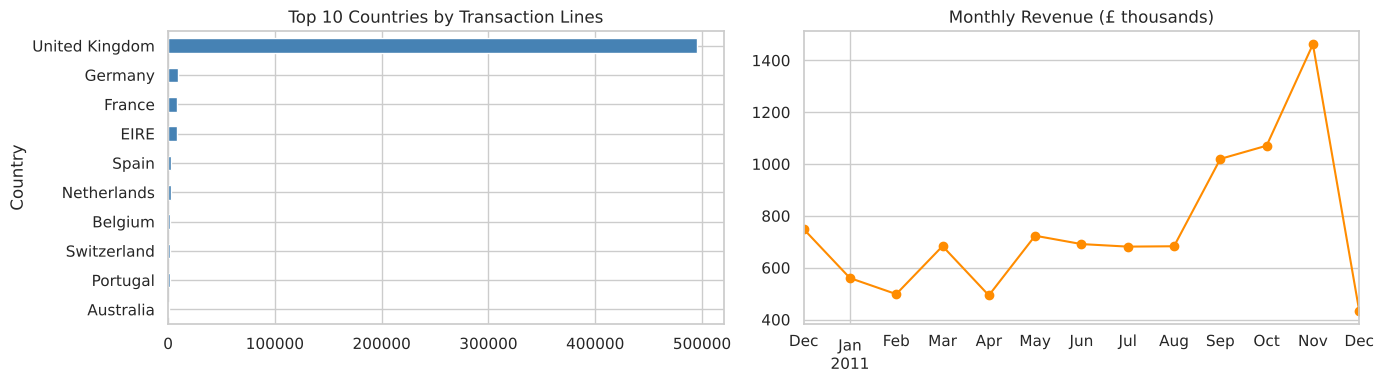

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df_raw["Country"].value_counts().head(10).plot.barh(ax=ax[0], color="steelblue")
ax[0].invert_yaxis(); ax[0].set_title("Top 10 Countries by Transaction Lines")
monthly = (df_raw.assign(Rev=df_raw.Quantity * df_raw.UnitPrice)
                 .groupby(df_raw.InvoiceDate.dt.to_period("M"))["Rev"].sum() / 1e3)
monthly.plot(ax=ax[1], marker="o", color="darkorange")
ax[1].set_title("Monthly Revenue (£ thousands)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Observations:** ~25% of rows have no `CustomerID` (they cannot be attributed to a customer, so they are unusable for
customer-level segmentation). Cancellations, negative quantities, zero prices and duplicates must also be removed.
The UK dominates the data, and revenue peaks in Sep–Nov (pre-Christmas gift season).

## 6. Data Preprocessing
| Step | Issue | Treatment | Reason |
|---|---|---|---|
| 1 | Missing `CustomerID` | Drop rows | Cannot be linked to a customer; imputing IDs would invent customers |
| 2 | Cancellations (`C` invoices) | Remove | They reverse purchases and distort spend/frequency |
| 3 | Quantity ≤ 0 or UnitPrice ≤ 0 | Remove | Returns, adjustments, free samples — not genuine purchases |
| 4 | Duplicate rows | Remove | Double-counting |
| 5 | — | Add `TotalPrice = Quantity × UnitPrice` | Line-level revenue |

In [6]:
df = df_raw.copy()
log = [("Raw data", len(df))]

df = df.dropna(subset=["CustomerID"]);                       log.append(("Drop missing CustomerID", len(df)))
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")];   log.append(("Remove cancellations", len(df)))
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)];       log.append(("Keep Quantity>0 & UnitPrice>0", len(df)))
df = df.drop_duplicates();                                   log.append(("Remove duplicates", len(df)))

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(pd.DataFrame(log, columns=["Step", "Rows remaining"]).to_string(index=False))
print(f"\nClean transactions: {len(df):,}  |  Unique customers: {df.CustomerID.nunique():,}")

                         Step  Rows remaining
                     Raw data          541909
      Drop missing CustomerID          406829
         Remove cancellations          397924
Keep Quantity>0 & UnitPrice>0          397884
            Remove duplicates          392692

Clean transactions: 392,692  |  Unique customers: 4,338


## 7. Customer-Level Feature Engineering
Transactions are aggregated to **one row per customer**. Reference ("snapshot") date = last invoice date + 1 day.

| Feature | Definition |
|---|---|
| **Recency** | Days since the customer's last purchase (lower = better) |
| **Frequency** | Number of distinct invoices |
| **Monetary** | Total spend (£) |
| **AvgTransactionValue** | Monetary / Frequency |
| **TotalQuantity** | Total units purchased |
| **AvgQuantityPerInvoice** | TotalQuantity / Frequency |
| **UniqueProducts** | Number of distinct products bought (breadth) |
| **Tenure** | Days since first purchase |
| **PurchaseFrequency** | Invoices per month of tenure |

In [7]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)
g = df.groupby("CustomerID")

cust = pd.DataFrame({
    "Recency":        (snapshot - g["InvoiceDate"].max()).dt.days,
    "Frequency":      g["InvoiceNo"].nunique(),
    "Monetary":       g["TotalPrice"].sum(),
    "TotalQuantity":  g["Quantity"].sum(),
    "UniqueProducts": g["StockCode"].nunique(),
    "Tenure":         (snapshot - g["InvoiceDate"].min()).dt.days,
})
cust["AvgTransactionValue"]   = cust["Monetary"] / cust["Frequency"]
cust["AvgQuantityPerInvoice"] = cust["TotalQuantity"] / cust["Frequency"]
cust["PurchaseFrequency"]     = cust["Frequency"] / (cust["Tenure"] / 30).clip(lower=1)

FEATURES = ["Recency", "Frequency", "Monetary", "AvgTransactionValue", "TotalQuantity",
            "AvgQuantityPerInvoice", "UniqueProducts", "Tenure", "PurchaseFrequency"]
cust = cust[FEATURES]
print("Snapshot date:", snapshot.date(), "| Customer table:", cust.shape)
cust.describe().T

Snapshot date: 2011-12-10 | Customer table: (4338, 9)


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.000000,18.000000,51.000000,142.000000,374.000000
Frequency,4338.0,4.272015,7.697998,1.000000,1.000000,2.000000,5.000000,209.000000
Monetary,4338.0,2048.688081,8985.230220,3.750000,306.482500,668.570000,1660.597500,280206.020000
AvgTransactionValue,4338.0,417.645735,1796.511343,3.450000,177.867083,291.940000,428.280625,84236.250000
TotalQuantity,4338.0,1187.644537,5043.619654,1.000000,159.000000,378.000000,989.750000,196915.000000
AvgQuantityPerInvoice,4338.0,252.462892,1312.769337,1.000000,92.000000,161.000000,270.000000,74215.000000
UniqueProducts,4338.0,61.501153,85.366768,1.000000,16.000000,35.000000,77.000000,1787.000000
Tenure,4338.0,223.308207,117.886471,1.000000,113.000000,249.000000,327.000000,374.000000
PurchaseFrequency,4338.0,0.636579,0.737999,0.080214,0.232784,0.447761,0.813192,16.764706


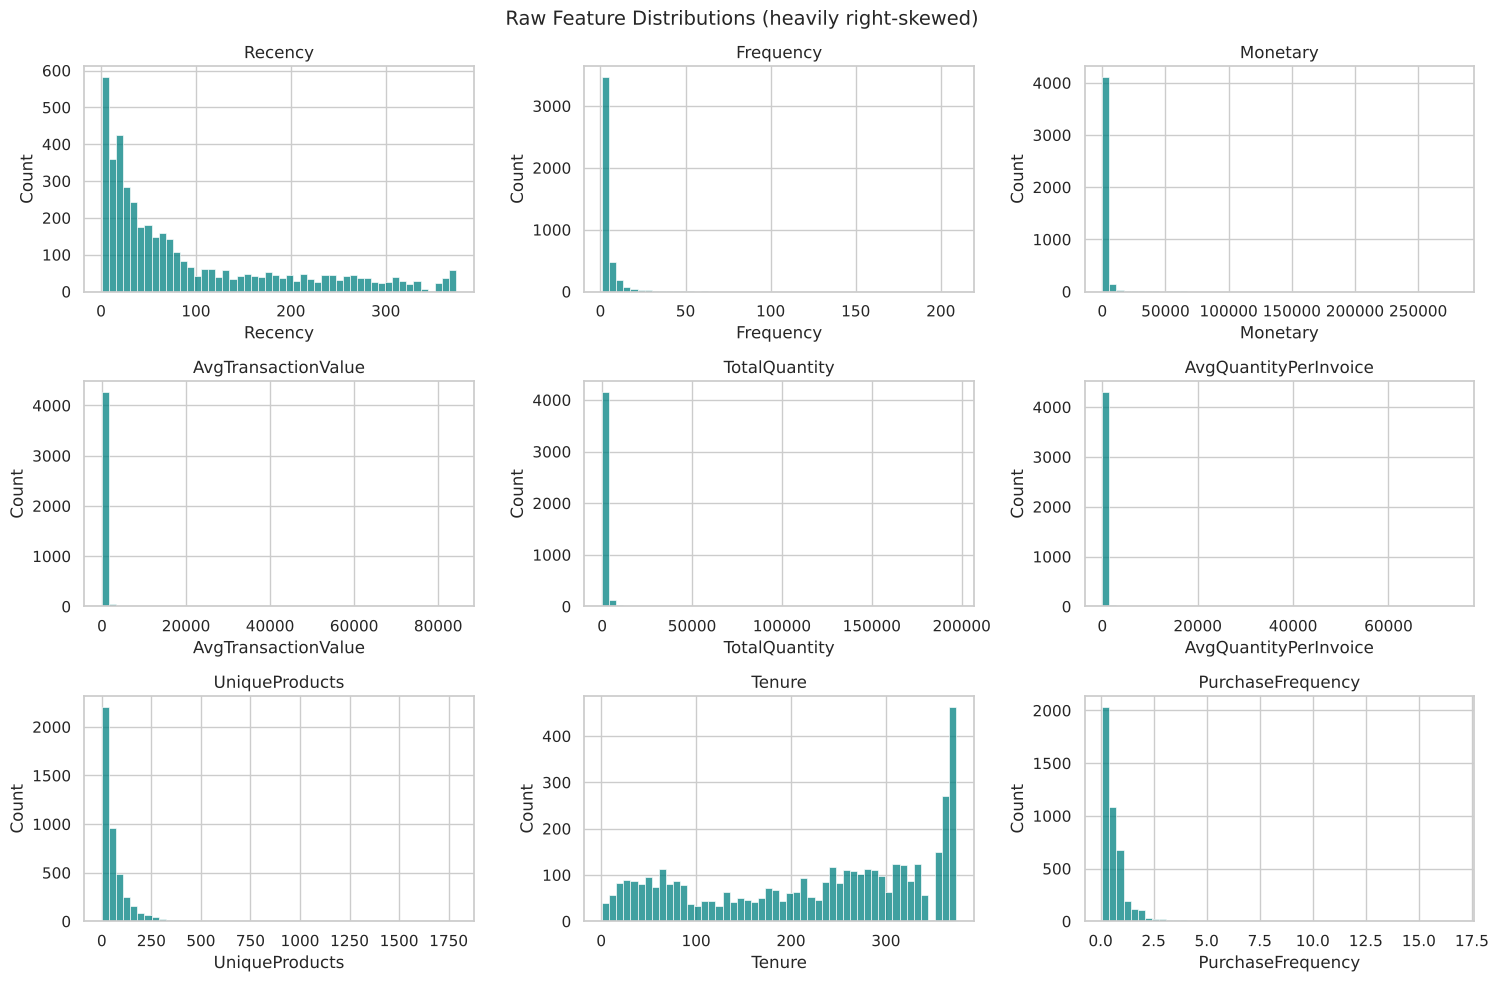

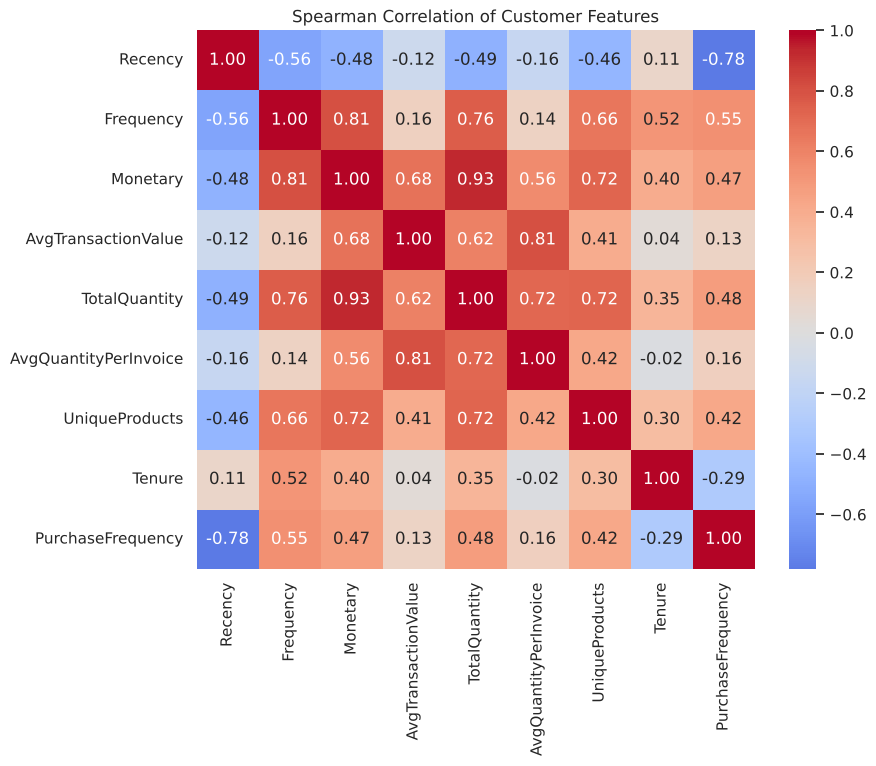

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(cust[col], bins=50, ax=ax, color="teal"); ax.set_title(col)
plt.suptitle("Raw Feature Distributions (heavily right-skewed)", fontsize=14); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(cust.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman Correlation of Customer Features"); plt.show()

## 8. Outlier Treatment and Feature Scaling
The boxplots below show extreme outliers (e.g., wholesale buyers spending > £200k). Distance-based algorithms like K-Means
are dominated by such points, so we apply three steps:

1. **Winsorization (capping)** at the 1st and 99th percentiles — keeps every customer but limits extreme values.
2. **log(1 + x) transform** — reduces right skew so that differences are measured on a relative scale.
3. **StandardScaler** (mean 0, std 1) — puts all features on a comparable scale so no single feature dominates distances.

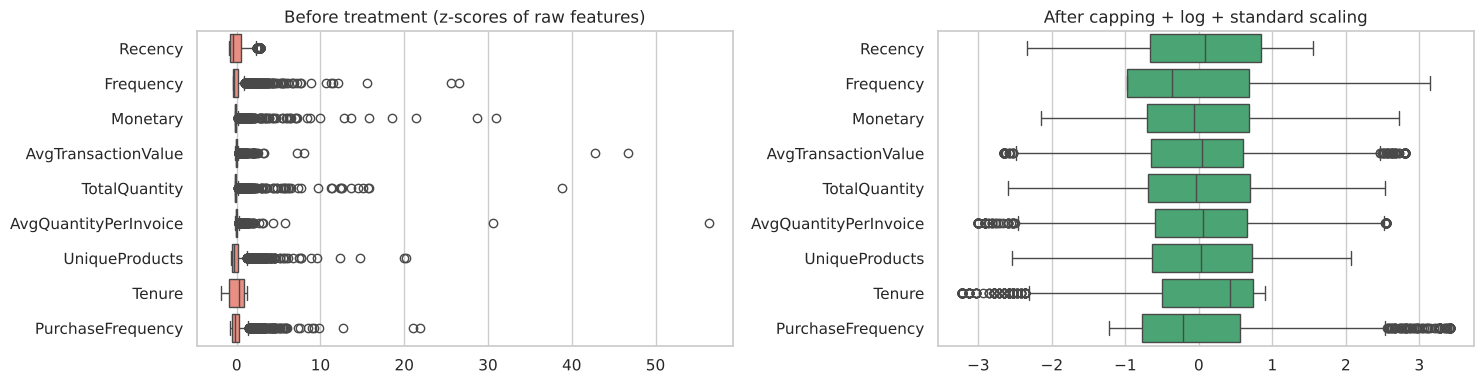

Customers with at least one capped value: 298 (6.9%)


,mean,std,min,max
Recency,-4.913850e-18,1.000115,-2.341486,1.554427
Frequency,6.388005e-17,1.000115,-0.974100,3.148252
Monetary,-4.062116e-16,1.000115,-2.150485,2.724304
AvgTransactionValue,7.731124e-16,1.000115,-2.643515,2.811752
TotalQuantity,-3.472454e-16,1.000115,-2.594034,2.527804
AvgQuantityPerInvoice,1.533121e-15,1.000115,-2.999034,2.552697
UniqueProducts,-8.189750e-17,1.000115,-2.543219,2.070610
Tenure,-2.031058e-16,1.000115,-3.222732,0.894771
PurchaseFrequency,-1.441396e-16,1.000115,-1.222740,3.411943


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=(cust - cust.mean()) / cust.std(), orient="h", ax=ax[0], color="salmon")
ax[0].set_title("Before treatment (z-scores of raw features)")

cust_capped = cust.copy()
for col in FEATURES:
    lo, hi = cust[col].quantile([0.01, 0.99])
    cust_capped[col] = cust[col].clip(lo, hi)
cust_log = np.log1p(cust_capped)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(cust_log), index=cust.index, columns=FEATURES)

sns.boxplot(data=X_scaled, orient="h", ax=ax[1], color="mediumseagreen")
ax[1].set_title("After capping + log + standard scaling")
plt.tight_layout(); plt.show()

n_capped = ((cust != cust_capped).any(axis=1)).sum()
print(f"Customers with at least one capped value: {n_capped} ({n_capped/len(cust):.1%})")
X_scaled.describe().T[["mean", "std", "min", "max"]]

## 9. Optimal Number of Clusters — Elbow Method (Deliverable 2)
We run K-Means for k = 2 … 10 and plot the **within-cluster sum of squares (WCSS / inertia)**. The "elbow" is where
adding another cluster stops giving a large reduction. The Silhouette Score for each k is plotted alongside as a second opinion.

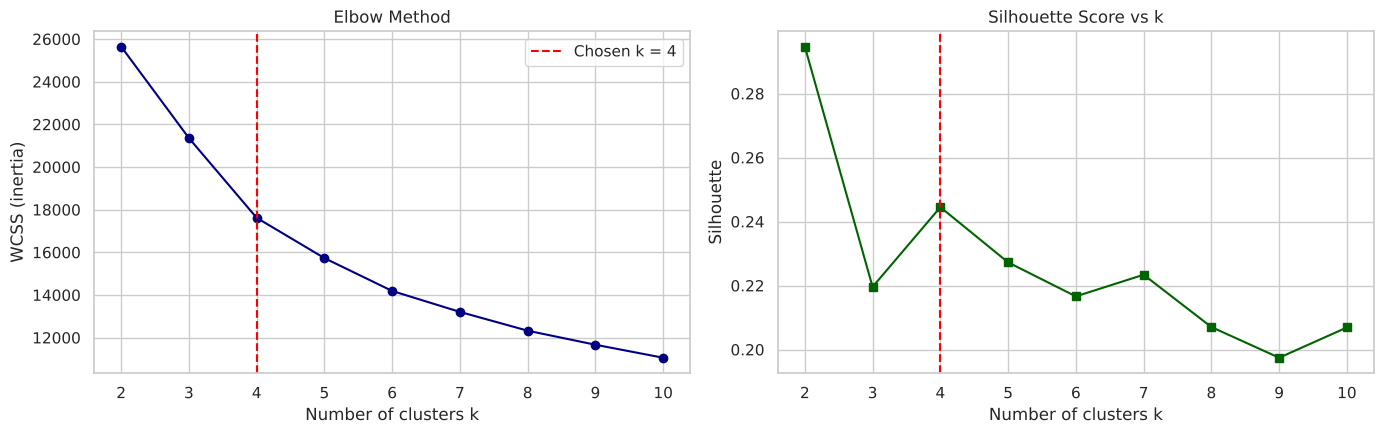

 k    WCSS  Silhouette  WCSS drop %
 2 25648.0       0.295          NaN
 3 21359.0       0.220         16.7
 4 17618.0       0.244         17.5
 5 15729.0       0.227         10.7
 6 14188.0       0.217          9.8
 7 13206.0       0.223          6.9
 8 12324.0       0.207          6.7
 9 11666.0       0.197          5.3
10 11057.0       0.207          5.2


In [10]:
K_RANGE = range(2, 11)
wcss, sil = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(list(K_RANGE), wcss, "o-", color="navy")
ax[0].axvline(4, ls="--", color="red", label="Chosen k = 4"); ax[0].legend()
ax[0].set(title="Elbow Method", xlabel="Number of clusters k", ylabel="WCSS (inertia)")
ax[1].plot(list(K_RANGE), sil, "s-", color="darkgreen")
ax[1].axvline(4, ls="--", color="red")
ax[1].set(title="Silhouette Score vs k", xlabel="Number of clusters k", ylabel="Silhouette")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"k": list(K_RANGE), "WCSS": np.round(wcss), "Silhouette": np.round(sil, 3),
                    "WCSS drop %": np.r_[np.nan, -np.diff(wcss) / np.array(wcss[:-1]) * 100].round(1)}).to_string(index=False))

**Choosing k = 4.**
* The WCSS curve bends most sharply between k = 2 and k = 4; after k = 4 each additional cluster only reduces WCSS by ~10% or less.
* k = 2 has the highest silhouette, but a 2-way split ("good" vs "bad" customers) is too coarse for targeted marketing.
* Silhouette **rises again at k = 4** (a local peak over k = 3 and k = 5), so k = 4 is both statistically supported and
  gives business-meaningful segments.

## 10. K-Means Customer Segmentation (Deliverable 3)

In [11]:
K_OPT = 4
kmeans = KMeans(n_clusters=K_OPT, n_init=20, random_state=RANDOM_STATE)
cust["KMeans"] = kmeans.fit_predict(X_scaled)

sil_km = silhouette_score(X_scaled, cust["KMeans"])
print(f"K-Means (k={K_OPT}) Silhouette Score: {sil_km:.3f}\n")
print(cust["KMeans"].value_counts().sort_index().rename("Customers"))

K-Means (k=4) Silhouette Score: 0.245

KMeans
0     726
1    1528
2    1112
3     972
Name: Customers, dtype: int64


### Automatic segment naming
Raw cluster numbers are arbitrary, so we name them from their profiles:
* highest average **Monetary** → **Champions (High-Value)**
* highest average **Recency** (longest since last purchase) → **Lost / Hibernating**
* shortest **Tenure** among the rest → **New / Recent Customers**
* remaining → **At-Risk Regulars** (mid-value, slipping away)

In [12]:
def name_segments(frame, label_col):
    prof = frame.groupby(label_col)[["Monetary", "Recency", "Tenure"]].mean()
    names, remaining = {}, list(prof.index)
    hv = prof["Monetary"].idxmax();                         names[hv] = "Champions (High-Value)";  remaining.remove(hv)
    lost = prof.loc[remaining, "Recency"].idxmax();         names[lost] = "Lost / Hibernating";    remaining.remove(lost)
    if remaining:
        new = prof.loc[remaining, "Tenure"].idxmin();       names[new] = "New / Recent Customers"; remaining.remove(new)
    for i, c in enumerate(remaining):
        names[c] = "At-Risk Regulars" if i == 0 else f"Segment {c}"
    return names

seg_names = name_segments(cust, "KMeans")
cust["Segment"] = cust["KMeans"].map(seg_names)
SEG_ORDER = ["Champions (High-Value)", "At-Risk Regulars", "New / Recent Customers", "Lost / Hibernating"]
SEG_ORDER = [s for s in SEG_ORDER if s in cust["Segment"].unique()]
SEG_COLORS = dict(zip(SEG_ORDER, ["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728"]))
print(seg_names)
cust["Segment"].value_counts().reindex(SEG_ORDER)

{np.int32(3): 'Champions (High-Value)', np.int32(2): 'Lost / Hibernating', np.int32(0): 'New / Recent Customers', 1: 'At-Risk Regulars'}


Segment
Champions (High-Value)     972
At-Risk Regulars          1528
New / Recent Customers     726
Lost / Hibernating        1112
Name: count, dtype: int64

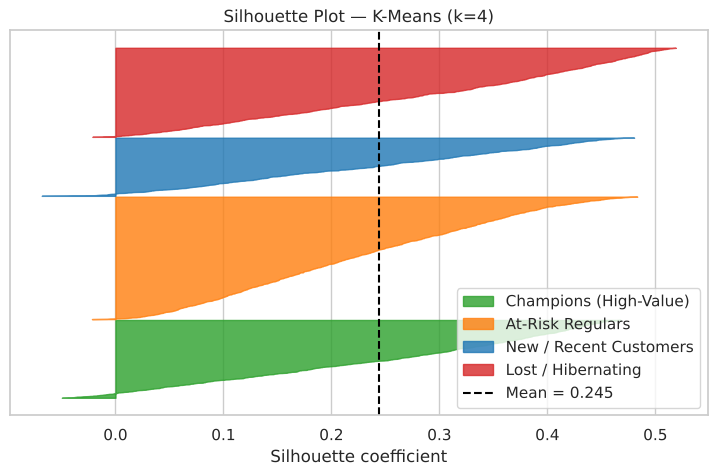

In [13]:
sample_sil = silhouette_samples(X_scaled, cust["KMeans"])
fig, ax = plt.subplots(figsize=(9, 5)); y0 = 10
for seg in SEG_ORDER:
    vals = np.sort(sample_sil[cust["Segment"] == seg])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=SEG_COLORS[seg], alpha=0.8, label=seg)
    y0 += len(vals) + 10
ax.axvline(sil_km, color="black", ls="--", label=f"Mean = {sil_km:.3f}")
ax.set(title="Silhouette Plot — K-Means (k=4)", xlabel="Silhouette coefficient", yticks=[]); ax.legend(loc="lower right")
plt.show()

## 11. Hierarchical Clustering and Dendrogram (Deliverable 4)
Agglomerative clustering with **Ward linkage** (merges the pair of clusters that least increases total within-cluster
variance — the same objective as K-Means, which makes the comparison fair). The dendrogram is truncated to the last 30
merges for readability.

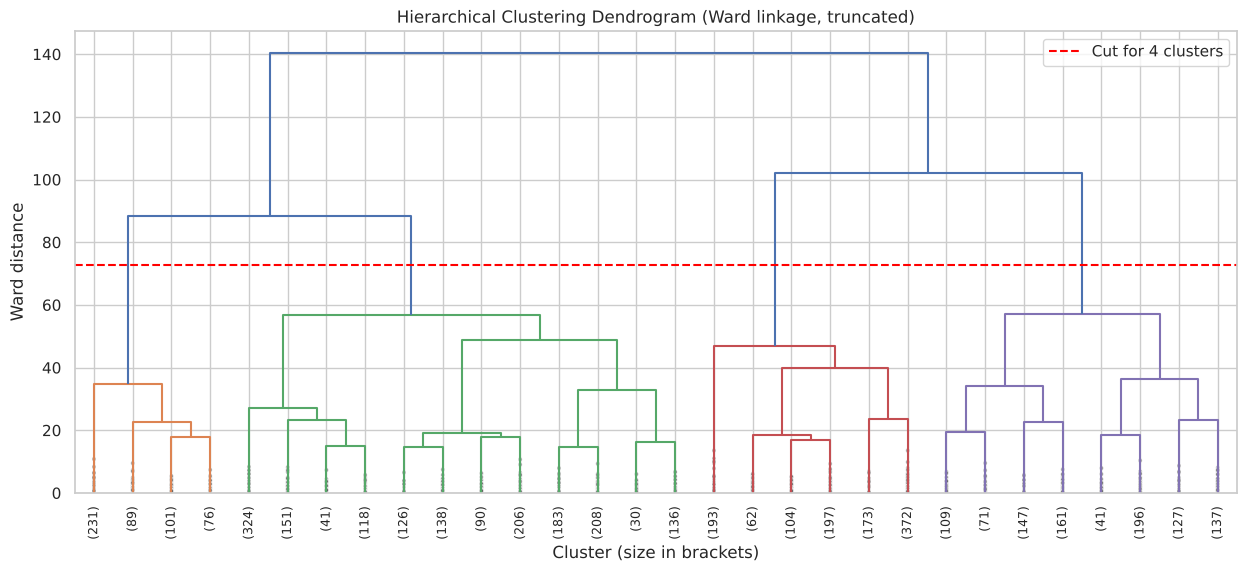

In [14]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=Z[-(K_OPT - 1), 2])
cut = (Z[-K_OPT, 2] + Z[-(K_OPT - 1), 2]) / 2
plt.axhline(cut, color="red", ls="--", label=f"Cut for {K_OPT} clusters")
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, truncated)")
plt.xlabel("Cluster (size in brackets)"); plt.ylabel("Ward distance"); plt.legend(); plt.show()

In [15]:
hier = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward")
cust["Hierarchical"] = hier.fit_predict(X_scaled)
sil_hc = silhouette_score(X_scaled, cust["Hierarchical"])
print(f"Hierarchical (Ward, k={K_OPT}) Silhouette Score: {sil_hc:.3f}")
cust["Hierarchical"].value_counts().sort_index().rename("Customers")

Hierarchical (Ward, k=4) Silhouette Score: 0.200


Hierarchical
0     989
1    1751
2    1101
3     497
Name: Customers, dtype: int64

## 12. Silhouette Score and Comparison of Clustering Results (Deliverable 5)

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Smallest cluster,Largest cluster
K-Means,0.245,1.238,1756.729,726,1528
Hierarchical (Ward),0.200,1.380,1363.871,497,1751


Adjusted Rand Index (agreement between the two methods): 0.481


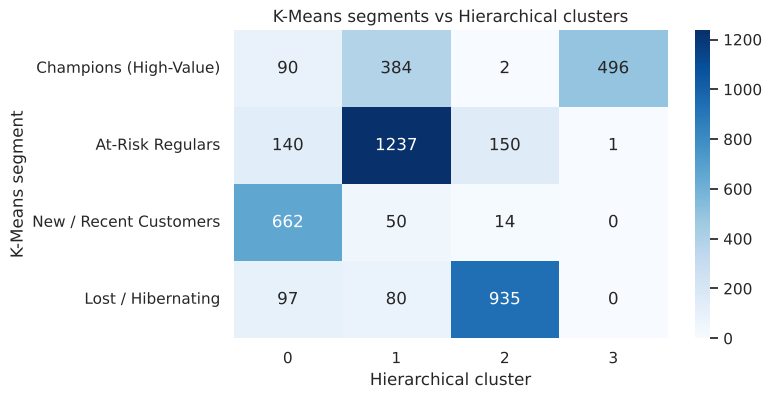

In [16]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

comparison = pd.DataFrame({
    "Silhouette (↑)":        [sil_km, sil_hc],
    "Davies-Bouldin (↓)":    [davies_bouldin_score(X_scaled, cust.KMeans), davies_bouldin_score(X_scaled, cust.Hierarchical)],
    "Calinski-Harabasz (↑)": [calinski_harabasz_score(X_scaled, cust.KMeans), calinski_harabasz_score(X_scaled, cust.Hierarchical)],
    "Smallest cluster":      [cust.KMeans.value_counts().min(), cust.Hierarchical.value_counts().min()],
    "Largest cluster":       [cust.KMeans.value_counts().max(), cust.Hierarchical.value_counts().max()],
}, index=["K-Means", "Hierarchical (Ward)"])
ari = adjusted_rand_score(cust.KMeans, cust.Hierarchical)
display(comparison.round(3))
print(f"Adjusted Rand Index (agreement between the two methods): {ari:.3f}")

plt.figure(figsize=(7, 4))
sns.heatmap(pd.crosstab(cust["Segment"], cust["Hierarchical"]).reindex(SEG_ORDER), annot=True, fmt="d", cmap="Blues")
plt.title("K-Means segments vs Hierarchical clusters"); plt.xlabel("Hierarchical cluster"); plt.ylabel("K-Means segment")
plt.show()

**Interpretation.**
* **K-Means achieves the better Silhouette, Davies-Bouldin and Calinski-Harabasz scores**, so its clusters are more compact and better separated.
* An ARI of about 0.5 shows **moderate agreement**: both methods find the same broad structure (the high-value group and the
  lost group are largely shared), but they draw the boundaries between the middle groups differently.
* Silhouette values around 0.2–0.25 are typical for real customer data, where behaviour varies continuously rather than in
  well-separated groups. The segments are still clearly distinct in their profiles (Section 14).
* **Decision:** K-Means is used for profiling and for the predictive task. It is also cheaper (O(n) vs O(n²) memory) and
  can assign new customers to a segment directly with `predict`.

## 13. PCA — Dimensionality Reduction and 2D Visualisation (Deliverable 6)
PCA projects the 9 standardised features onto orthogonal components that capture the most variance.

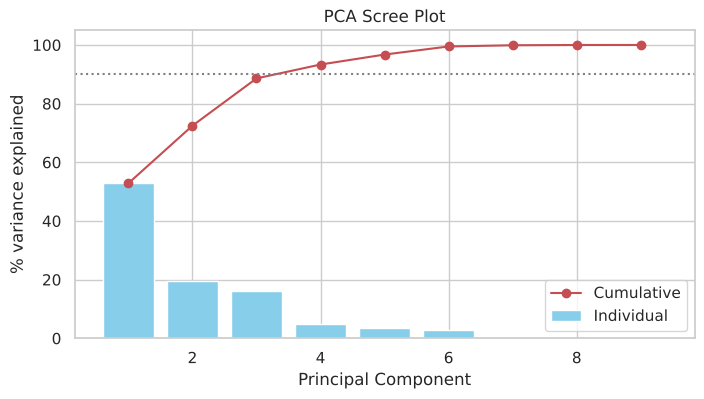

Cumulative variance: [ 52.8  72.5  88.6  93.3  96.7  99.5  99.9 100.  100. ]


,PC1,PC2,PC3
Recency,-0.283,-0.483,0.035
Frequency,0.369,0.168,0.430
Monetary,0.440,-0.097,0.080
AvgTransactionValue,0.298,-0.362,-0.405
TotalQuantity,0.441,-0.110,-0.001
AvgQuantityPerInvoice,0.302,-0.327,-0.449
UniqueProducts,0.362,-0.014,0.107
Tenure,0.104,-0.424,0.645
PurchaseFrequency,0.272,0.546,-0.122


In [17]:
pca_full = PCA().fit(X_scaled)
evr = pca_full.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 10), evr * 100, color="skyblue", label="Individual")
ax.plot(range(1, 10), np.cumsum(evr) * 100, "ro-", label="Cumulative")
ax.axhline(90, ls=":", color="grey")
ax.set(xlabel="Principal Component", ylabel="% variance explained", title="PCA Scree Plot"); ax.legend(); plt.show()
print("Cumulative variance:", np.round(np.cumsum(evr) * 100, 1))

pca = PCA(n_components=3, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
cust[["PC1", "PC2", "PC3"]] = pcs
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
loadings.round(3)

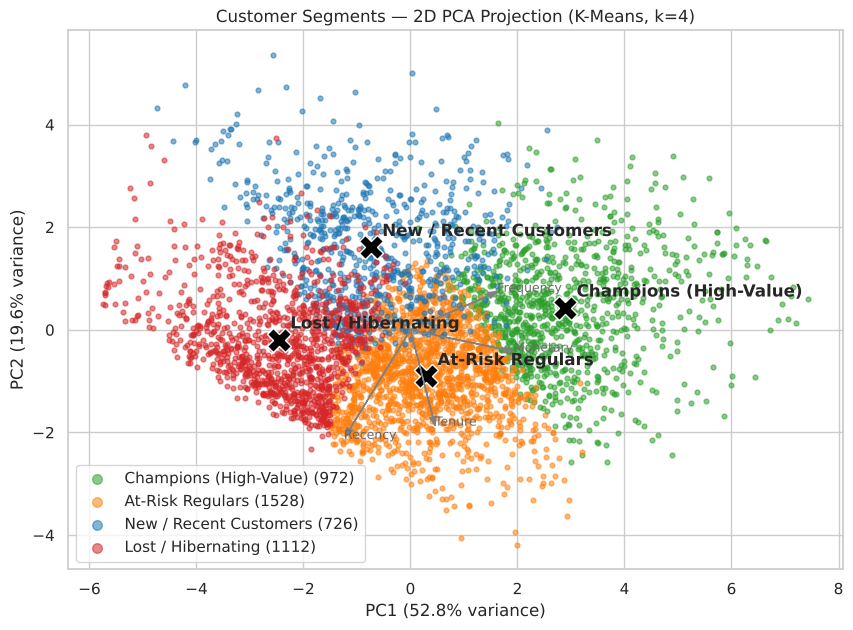

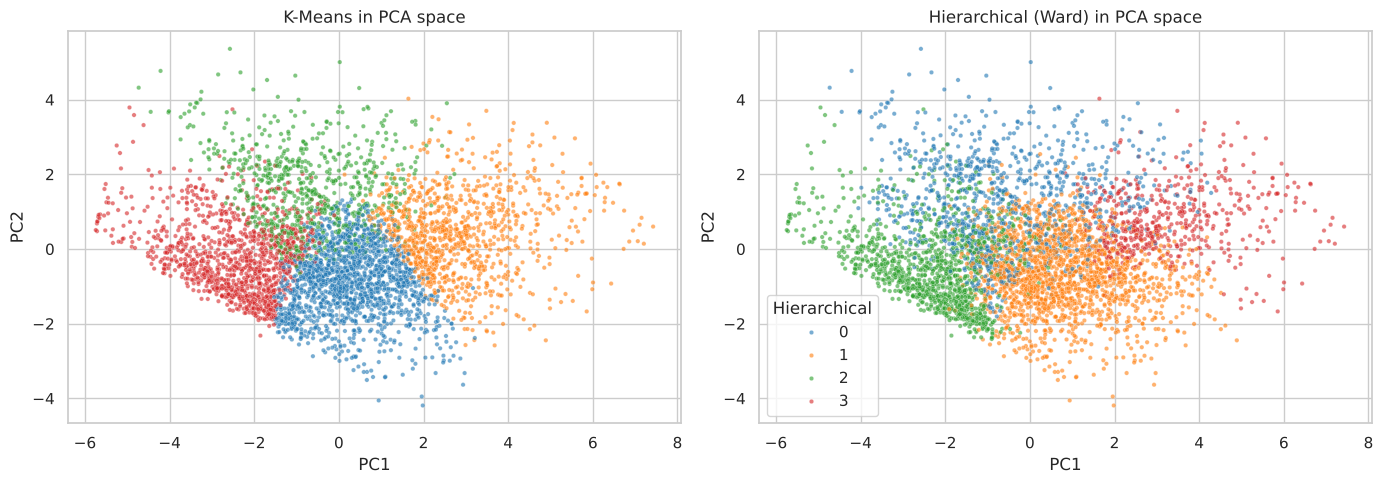

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))
for seg in SEG_ORDER:
    m = cust["Segment"] == seg
    ax.scatter(cust.loc[m, "PC1"], cust.loc[m, "PC2"], s=12, alpha=0.55, color=SEG_COLORS[seg], label=f"{seg} ({m.sum()})")
cent = pca.transform(kmeans.cluster_centers_)
for i, (x, y, _) in enumerate(cent):
    ax.scatter(x, y, marker="X", s=300, color="black", edgecolor="white")
    ax.annotate(seg_names[i], (x, y), xytext=(8, 8), textcoords="offset points", fontweight="bold")
# loading arrows
for f in ["Monetary", "Frequency", "Recency", "Tenure"]:
    ax.arrow(0, 0, loadings.loc[f, "PC1"] * 4, loadings.loc[f, "PC2"] * 4, color="grey", head_width=0.12)
    ax.text(loadings.loc[f, "PC1"] * 4.4, loadings.loc[f, "PC2"] * 4.4, f, color="dimgrey", fontsize=9)
ax.set(xlabel=f"PC1 ({evr[0]:.1%} variance)", ylabel=f"PC2 ({evr[1]:.1%} variance)",
       title="Customer Segments — 2D PCA Projection (K-Means, k=4)")
ax.legend(markerscale=2); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, col, title in [(ax[0], "Segment", "K-Means"), (ax[1], "Hierarchical", "Hierarchical (Ward)")]:
    sns.scatterplot(x=cust.PC1, y=cust.PC2, hue=cust[col], s=10, alpha=0.6, ax=a, palette="tab10", legend=(col == "Hierarchical"))
    a.set_title(f"{title} in PCA space")
plt.tight_layout(); plt.show()

**Reading the PCA plot.** PC1 is driven mostly by spend, frequency, quantity and product breadth (an overall
**"customer value / engagement"** axis); PC2 contrasts **recent, high-rate, short-tenure** buyers (high PurchaseFrequency, low Recency) with long-standing,
less-recent customers (high Tenure/Recency) — a **"lifecycle stage"** axis.
The Champions sit at the high-value end of PC1, Lost customers at the opposite end, and the New vs At-Risk groups are separated
mainly along PC2 — confirming that the segments are distinct on interpretable behavioural axes.

## 14. Cluster-wise Customer Profiling and Interpretation (Deliverable 7)

In [19]:
profile = cust.groupby("Segment")[FEATURES].mean().reindex(SEG_ORDER)
profile.insert(0, "Customers", cust["Segment"].value_counts())
profile.insert(1, "% Customers", (profile["Customers"] / len(cust) * 100).round(1))
rev = cust.groupby("Segment")["Monetary"].sum()
profile.insert(2, "% Revenue", (rev / rev.sum() * 100).round(1))
display(profile.round(1))

median_prof = cust.groupby("Segment")[["Recency", "Frequency", "Monetary", "AvgTransactionValue"]].median().reindex(SEG_ORDER)
print("Median values (robust to outliers):"); display(median_prof.round(1))

,Customers,% Customers,% Revenue,Recency,Frequency,Monetary,AvgTransactionValue,TotalQuantity,AvgQuantityPerInvoice,UniqueProducts,Tenure,PurchaseFrequency
Segment,,,,,,,,,,,,
Champions (High-Value),972,22.4,72.6,19.6,11.7,6634.2,594.9,3812.1,342.9,145.5,296.4,1.2
At-Risk Regulars,1528,35.2,20.6,101.6,2.7,1196.0,541.9,729.7,351.0,54.5,247.6,0.4
New / Recent Customers,726,16.7,3.6,28.9,1.6,437.9,292.8,268.4,184.4,32.9,43.8,1.1
Lost / Hibernating,1112,25.6,3.3,185.4,1.7,263.9,173.6,123.1,82.5,16.3,243.2,0.2


Median values (robust to outliers):


,Recency,Frequency,Monetary,AvgTransactionValue
Segment,,,,
Champions (High-Value),11.0,8.0,3096.1,371.7
At-Risk Regulars,73.0,2.5,882.5,359.2
New / Recent Customers,25.0,1.0,348.9,245.8
Lost / Hibernating,186.5,1.0,225.2,150.9


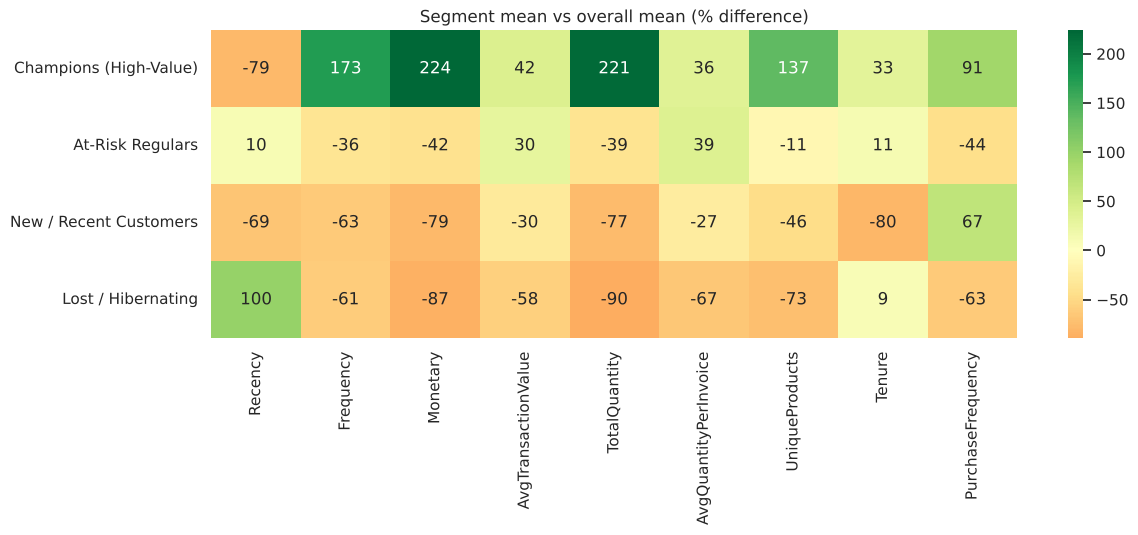

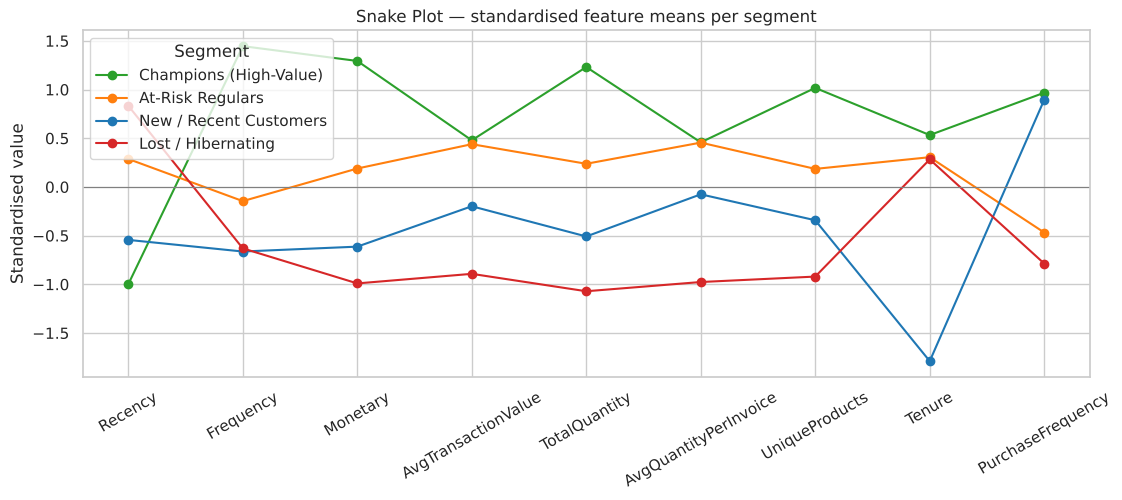

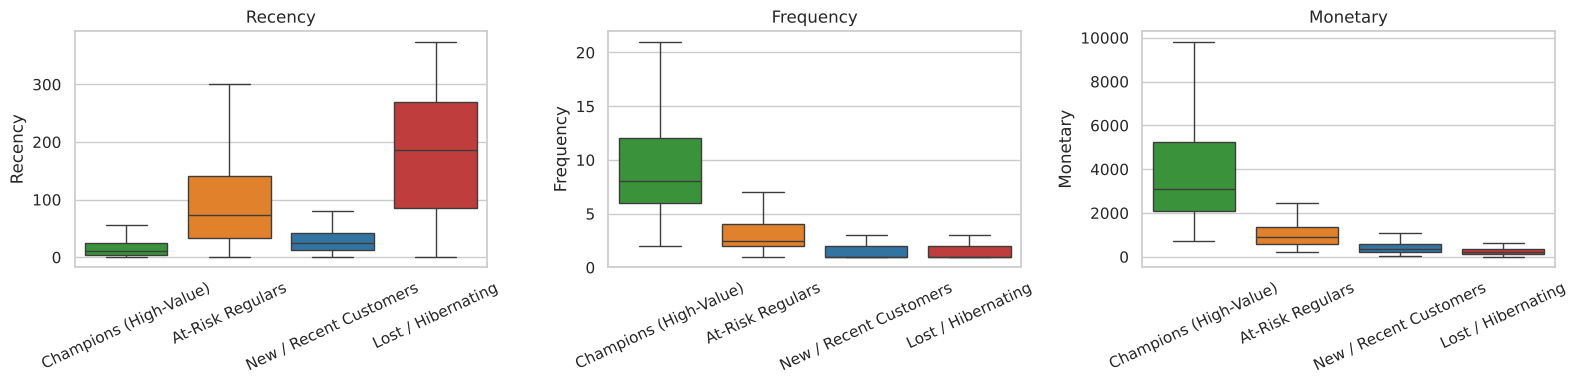

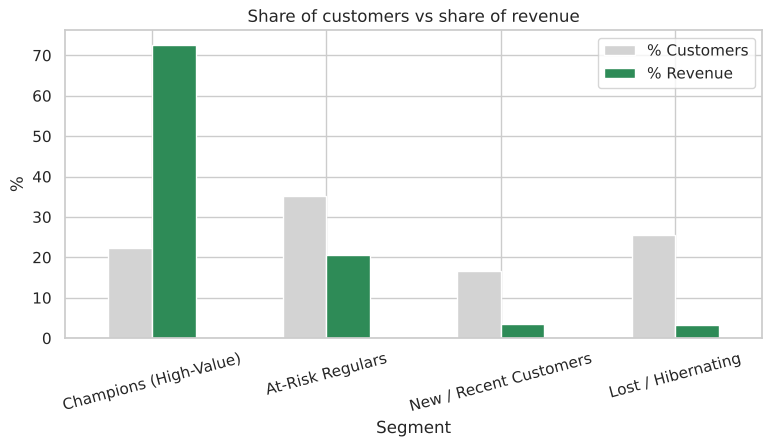

In [20]:
# Relative importance heatmap: how far each segment's mean is from the overall mean
rel = (cust.groupby("Segment")[FEATURES].mean() / cust[FEATURES].mean() - 1).reindex(SEG_ORDER) * 100
plt.figure(figsize=(13, 4))
sns.heatmap(rel, annot=True, fmt=".0f", cmap="RdYlGn", center=0)
plt.title("Segment mean vs overall mean (% difference)"); plt.ylabel(""); plt.show()

# Snake plot on scaled features
snake = X_scaled.assign(Segment=cust["Segment"]).groupby("Segment").mean().reindex(SEG_ORDER).T
snake.plot(figsize=(13, 4.5), marker="o", color=[SEG_COLORS[s] for s in SEG_ORDER])
plt.title("Snake Plot — standardised feature means per segment"); plt.xticks(range(len(FEATURES)), FEATURES, rotation=30)
plt.ylabel("Standardised value"); plt.axhline(0, color="grey", lw=0.8); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=cust, x="Segment", y=col, order=SEG_ORDER, palette=SEG_COLORS, ax=a, showfliers=False)
    a.set_title(col); a.tick_params(axis="x", rotation=25); a.set_xlabel("")
plt.tight_layout(); plt.show()

share = profile[["% Customers", "% Revenue"]]
share.plot.bar(figsize=(9, 4), color=["lightgrey", "seagreen"]); plt.title("Share of customers vs share of revenue")
plt.xticks(rotation=15); plt.ylabel("%"); plt.show()

### Segment profiles

| Segment | Behaviour | Business meaning |
|---|---|---|
| **Champions (High-Value)** | Bought very recently (≈ 3 weeks), ~12 orders, highest spend, widest product range, longest tenure | ~22% of customers generate roughly **70% of revenue** — the core of the business |
| **At-Risk Regulars** | Mid recency (≈ 3 months), 2–3 orders, moderate spend | Previously engaged customers who are slowing down; worth reactivating before they lapse |
| **New / Recent Customers** | Very recent but short tenure, 1–2 orders, low-to-moderate spend | Newly acquired; the key goal is the 2nd and 3rd purchase |
| **Lost / Hibernating** | Last purchase ≈ 6 months ago, ~1–2 orders, lowest spend | Mostly one-time buyers; low return on marketing spend |

*(Exact figures are in the tables above — they are computed by the notebook.)* This is a classic **Pareto pattern**:
a small group of loyal customers drives most of the revenue.

## 15. High-Value Customer Prediction (Deliverable 8)
### 15.1 Target definition
The **Champions (High-Value)** segment is chosen as the high-value class because it has the highest spend, highest frequency,
best recency and the largest revenue contribution.

`HighValue = 1` if the customer is in Champions, else `0`.

**Why build a classifier if clusters already exist?** The classifier turns the segmentation into a reusable, fast scoring
rule: new or updated customers can be scored in real time (e.g., in a CRM) without re-running clustering, and it gives
calibrated probabilities that can rank customers for campaigns.

**Note on leakage (critical reasoning):** the label is derived from the same features, so a very high score is expected
— the model is learning the cluster boundary. In Section 15.6 we also train a stricter model **without** the spend
features to test whether high value can be recognised from behaviour alone.

In [21]:
HV_SEGMENT = "Champions (High-Value)"
y = (cust["Segment"] == HV_SEGMENT).astype(int)
X = cust_log[FEATURES]          # capped + log-transformed features (scaling is done inside the pipelines)

print(y.value_counts().rename({0: "Not high-value", 1: "High-value"}))
print(f"High-value share: {y.mean():.1%}  -> moderate imbalance, so we stratify and use class_weight='balanced'")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Segment
Not high-value    3366
High-value         972
Name: count, dtype: int64
High-value share: 22.4%  -> moderate imbalance, so we stratify and use class_weight='balanced'
Train: (3253, 9)  Test: (1085, 9)


### 15.2 Model training with hyper-parameter tuning
Both models are wrapped in a `Pipeline` with `StandardScaler`, so scaling is fitted **only on the training data** (no
test-set leakage). Hyper-parameters are tuned with 5-fold stratified cross-validation optimising **F1**.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_pipe = Pipeline([("scaler", StandardScaler()),
                    ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))])
rf_grid = GridSearchCV(rf_pipe, {"clf__n_estimators": [200, 400],
                                 "clf__max_depth": [None, 8, 12],
                                 "clf__min_samples_leaf": [1, 3]},
                       scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)

svm_pipe = Pipeline([("scaler", StandardScaler()),
                     ("clf", SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE))])
svm_grid = GridSearchCV(svm_pipe, {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
                        scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)

models = {"Random Forest": rf_grid.best_estimator_, "SVM (RBF)": svm_grid.best_estimator_}
print("Random Forest best params:", rf_grid.best_params_, f"| CV F1 = {rf_grid.best_score_:.4f}")
print("SVM best params          :", svm_grid.best_params_, f"| CV F1 = {svm_grid.best_score_:.4f}")

Random Forest best params: {'clf__max_depth': 12, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200} | CV F1 = 0.9490
SVM best params          : {'clf__C': 100, 'clf__gamma': 0.01} | CV F1 = 0.9785


### 15.3 Performance comparison (Deliverable 9)

In [23]:
def evaluate(models, X_te, y_te):
    rows, probs = [], {}
    for name, m in models.items():
        pred = m.predict(X_te); prob = m.predict_proba(X_te)[:, 1]; probs[name] = prob
        rows.append({"Model": name,
                     "Accuracy":  accuracy_score(y_te, pred),
                     "Precision": precision_score(y_te, pred),
                     "Recall":    recall_score(y_te, pred),
                     "F1-Score":  f1_score(y_te, pred),
                     "ROC-AUC":   roc_auc_score(y_te, prob)})
    return pd.DataFrame(rows).set_index("Model"), probs

results, probs = evaluate(models, X_test, y_test)
display(results.round(4))

for name, m in models.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, m.predict(X_test), target_names=["Not high-value", "High-value"], digits=4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.9770,0.9325,0.9671,0.9495,0.9985
SVM (RBF),0.9917,0.9756,0.9877,0.9816,0.9998



===== Random Forest =====
                precision    recall  f1-score   support

Not high-value     0.9904    0.9798    0.9851       842
    High-value     0.9325    0.9671    0.9495       243

      accuracy                         0.9770      1085
     macro avg     0.9615    0.9734    0.9673      1085
  weighted avg     0.9774    0.9770    0.9771      1085


===== SVM (RBF) =====
                precision    recall  f1-score   support

Not high-value     0.9964    0.9929    0.9946       842
    High-value     0.9756    0.9877    0.9816       243

      accuracy                         0.9917      1085
     macro avg     0.9860    0.9903    0.9881      1085
  weighted avg     0.9918    0.9917    0.9917      1085



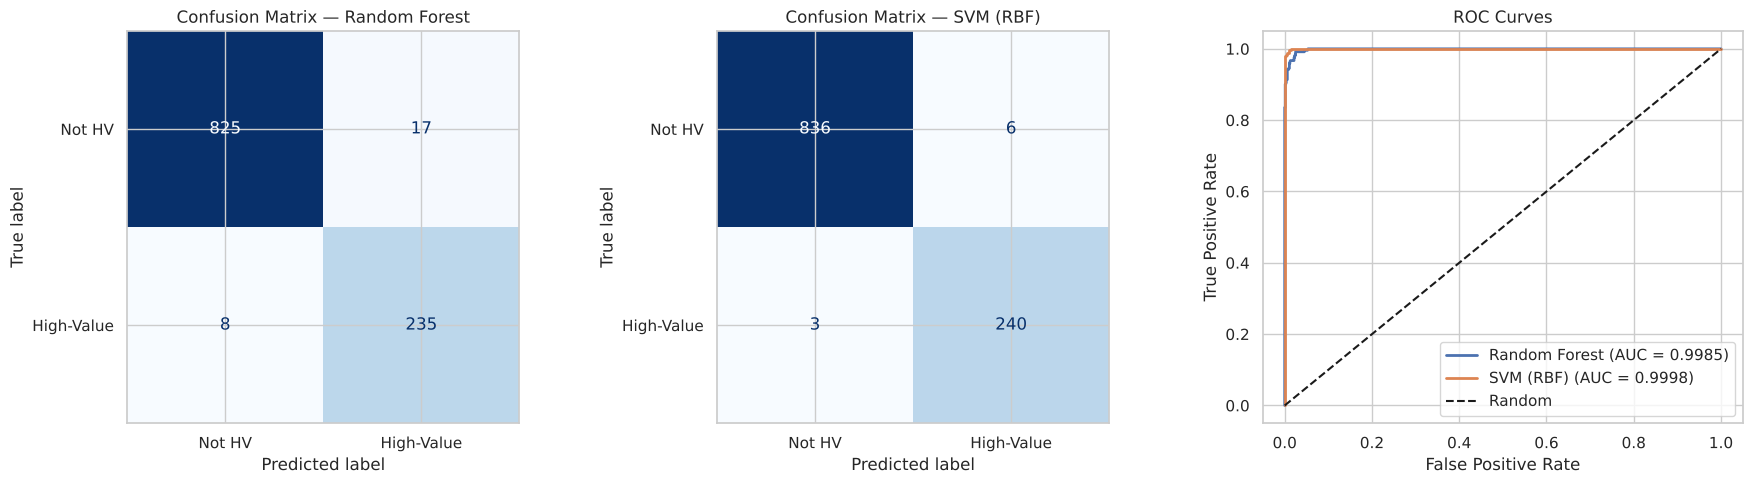

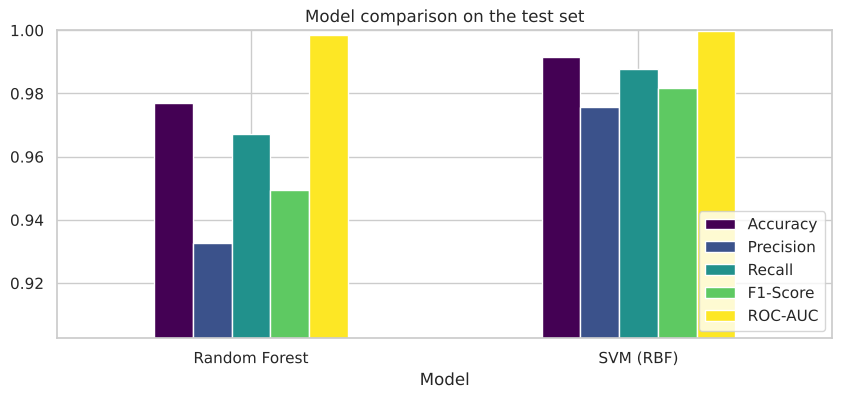

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, m) in zip(ax[:2], models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Not HV", "High-Value"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion Matrix — {name}")
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[2].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.4f})")
ax[2].plot([0, 1], [0, 1], "k--", label="Random"); ax[2].set(title="ROC Curves", xlabel="False Positive Rate",
                                                             ylabel="True Positive Rate"); ax[2].legend()
plt.tight_layout(); plt.show()

results.plot.bar(figsize=(10, 4), ylim=(results.min().min() - 0.03, 1.0), colormap="viridis")
plt.title("Model comparison on the test set"); plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

In [25]:
# Stability check: 5-fold cross-validated F1 and ROC-AUC on the full data
cv_rows = []
for name, m in models.items():
    for metric in ["f1", "roc_auc"]:
        s = cross_val_score(m, X, y, cv=cv, scoring=metric, n_jobs=-1)
        cv_rows.append({"Model": name, "Metric": metric, "Mean": s.mean(), "Std": s.std()})
pd.DataFrame(cv_rows).pivot(index="Model", columns="Metric", values=["Mean", "Std"]).round(4)

Mean             Std        
Metric             f1 roc_auc      f1 roc_auc
Model                                        
Random Forest  0.9525  0.9980  0.0107  0.0008
SVM (RBF)      0.9813  0.9998  0.0082  0.0002

### 15.4 Feature importance analysis (Deliverable 10)

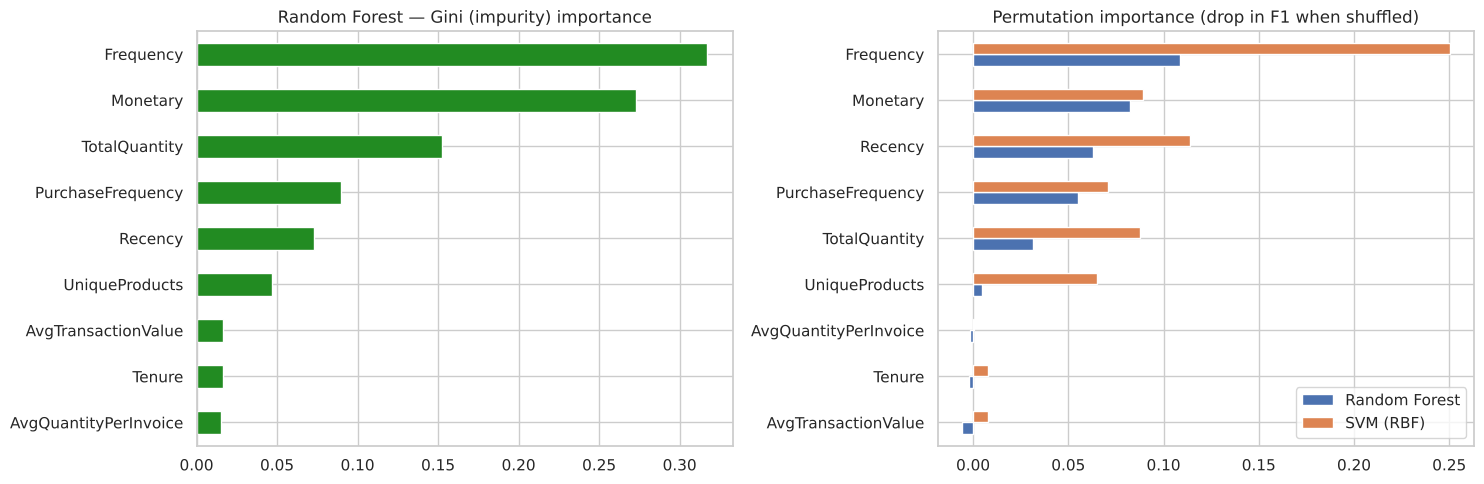

,RF Gini,Random Forest,SVM (RBF)
Frequency,0.3173,0.1085,0.2502
Monetary,0.2731,0.0825,0.0894
TotalQuantity,0.1526,0.0315,0.0878
PurchaseFrequency,0.0895,0.0551,0.0708
Recency,0.0728,0.0629,0.1140
UniqueProducts,0.0467,0.0049,0.0652
AvgTransactionValue,0.0166,-0.0059,0.0079
Tenure,0.0164,-0.0019,0.0076
AvgQuantityPerInvoice,0.0150,-0.0015,0.0003


In [26]:
rf_model = models["Random Forest"].named_steps["clf"]
imp_gini = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()

perm = {name: permutation_importance(m, X_test, y_test, scoring="f1", n_repeats=15,
                                     random_state=RANDOM_STATE, n_jobs=-1).importances_mean
        for name, m in models.items()}
imp_perm = pd.DataFrame(perm, index=FEATURES).sort_values("Random Forest")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
imp_gini.plot.barh(ax=ax[0], color="forestgreen"); ax[0].set_title("Random Forest — Gini (impurity) importance")
imp_perm.plot.barh(ax=ax[1]); ax[1].set_title("Permutation importance (drop in F1 when shuffled)")
plt.tight_layout(); plt.show()
display(pd.concat([imp_gini.rename("RF Gini"), imp_perm], axis=1).sort_values("RF Gini", ascending=False).round(4))

**Interpretation.** **Frequency** is the single most important feature, followed by **Monetary**, **Recency**,
**TotalQuantity** and **PurchaseFrequency**; tenure and average basket features contribute almost nothing. Permutation importance (model-agnostic, measured on unseen data) confirms the ranking for both models.
Gini importance spreads credit across correlated features (e.g., Monetary and TotalQuantity), so permutation importance is
the more reliable guide when features are correlated.

### 15.5 Model comparison summary

In [27]:
best = results["F1-Score"].idxmax()
print(results.round(4).to_string())
print(f"\nBest model by F1-Score: {best}")

               Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                        
Random Forest    0.9770     0.9325  0.9671    0.9495   0.9985
SVM (RBF)        0.9917     0.9756  0.9877    0.9816   0.9998

Best model by F1-Score: SVM (RBF)


* **Both models perform very well** (F1 and ROC-AUC close to 1), because the high-value segment is well separated in the
  RFM feature space.
* The **SVM (RBF)** matches the smooth, roughly spherical boundary that K-Means creates, so it is typically marginally
  more accurate here; **Random Forest** is almost as good and offers built-in feature importance and easier explanation to
  business users.
* Errors are concentrated near the segment boundary (customers who are "almost Champions") — these are actually useful
  targets for **up-sell campaigns**.

### 15.6 Robustness experiment — predicting high value without spend features
To check that the models are not just reading off the definition of the target, we remove the direct spend features
(`Monetary`, `AvgTransactionValue`) and retrain using **behaviour only** (recency, frequency, quantity, product breadth, tenure).

In [28]:
BEHAV = [f for f in FEATURES if f not in ["Monetary", "AvgTransactionValue"]]
models_b = {
    "Random Forest (behaviour only)": Pipeline([("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]),
    "SVM (behaviour only)": Pipeline([("scaler", StandardScaler()),
        ("clf", SVC(C=10, probability=True, class_weight="balanced", random_state=RANDOM_STATE))]),
}
for m in models_b.values():
    m.fit(X_train[BEHAV], y_train)
res_b, _ = evaluate(models_b, X_test[BEHAV], y_test)
display(pd.concat([results, res_b]).round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.9770,0.9325,0.9671,0.9495,0.9985
SVM (RBF),0.9917,0.9756,0.9877,0.9816,0.9998
Random Forest (behaviour only),0.9714,0.9206,0.9547,0.9374,0.9975
SVM (behaviour only),0.9816,0.9305,0.9918,0.9602,0.9987


Even without spend, the models still identify high-value customers with high accuracy — **purchase frequency, recency and
product breadth are strong behavioural signals of value**. This is practically useful: a customer who orders often and buys
a wide range of products can be flagged as a likely high-value customer early, before their total spend has accumulated.

## 16. Interactive 3D Visualisation with Plotly (Deliverable 11)
Rotate, zoom and hover over points to see each customer's details. (Interactive charts show as images or blank areas in a
printed PDF; the static fallback below is included for the PDF submission.)

In [29]:
plot_df = cust.reset_index()
fig = px.scatter_3d(plot_df, x="Recency", y="Frequency", z="Monetary", color="Segment",
                    category_orders={"Segment": SEG_ORDER}, color_discrete_map=SEG_COLORS,
                    log_y=True, log_z=True, opacity=0.65,
                    hover_data={"CustomerID": True, "AvgTransactionValue": ":.2f", "UniqueProducts": True},
                    title="Interactive 3D RFM View of Customer Segments (log scale on Frequency & Monetary)")
fig.update_traces(marker=dict(size=3)); fig.update_layout(height=650, legend=dict(itemsizing="constant"))
fig.show()

fig2 = px.scatter_3d(plot_df, x="PC1", y="PC2", z="PC3", color="Segment",
                     category_orders={"Segment": SEG_ORDER}, color_discrete_map=SEG_COLORS, opacity=0.65,
                     title=f"Customer Segments in 3D PCA Space ({np.cumsum(evr)[2]:.1%} variance explained)")
fig2.update_traces(marker=dict(size=3)); fig2.update_layout(height=650, legend=dict(itemsizing="constant"))
fig2.show()

fig.write_html("rfm_3d_clusters.html"); fig2.write_html("pca_3d_clusters.html")
print("Saved interactive HTML files: rfm_3d_clusters.html, pca_3d_clusters.html")

Saved interactive HTML files: rfm_3d_clusters.html, pca_3d_clusters.html


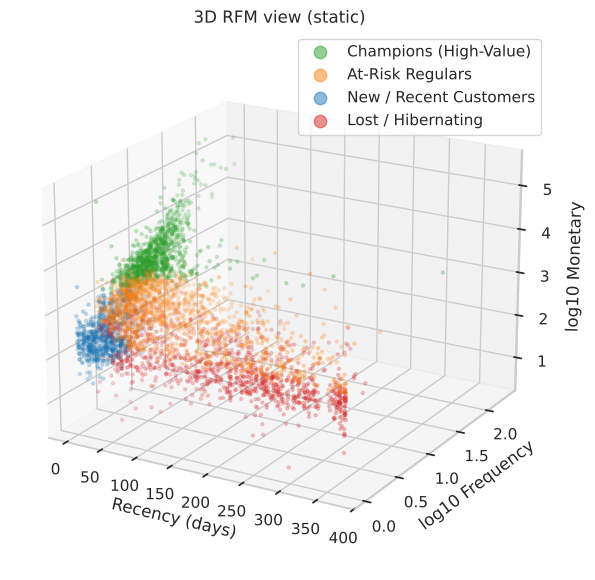

In [30]:
# Static 3D fallback (renders in the PDF export)
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(10, 7)); ax = fig.add_subplot(111, projection="3d")
for seg in SEG_ORDER:
    m = cust["Segment"] == seg
    ax.scatter(cust.loc[m, "Recency"], np.log10(cust.loc[m, "Frequency"]), np.log10(cust.loc[m, "Monetary"]),
               s=5, alpha=0.5, color=SEG_COLORS[seg], label=seg)
ax.set(xlabel="Recency (days)", ylabel="log10 Frequency", zlabel="log10 Monetary", title="3D RFM view (static)")
ax.view_init(elev=20, azim=-60); ax.legend(markerscale=4); plt.show()

## 17. Segment-wise Targeted Marketing Recommendations (Deliverable 12)

In [31]:
strategy = {
    "Champions (High-Value)": ("Retain & reward",
        "VIP loyalty tier, early access to new collections, personal account manager for wholesale buyers, "
        "referral rewards, bundle/upsell offers; avoid unnecessary discounts."),
    "At-Risk Regulars": ("Re-engage before they lapse",
        "Personalised 'we miss you' emails based on past purchases, time-limited win-back coupons (10–15%), "
        "free-shipping thresholds, feedback survey on why they stopped."),
    "New / Recent Customers": ("Convert to repeat buyers",
        "Welcome/onboarding email series, 2nd-order discount, product recommendations from their first basket, "
        "loyalty programme sign-up, cross-sell complementary items."),
    "Lost / Hibernating": ("Low-cost reactivation",
        "Automated low-cost campaigns only (seasonal sales, Christmas catalogue), deep one-off discount to test "
        "response; suppress non-responders to cut marketing cost."),
}
rec = profile[["Customers", "% Customers", "% Revenue", "Recency", "Frequency", "Monetary"]].copy()
rec["Objective"] = [strategy[s][0] for s in rec.index]
rec["Recommended actions"] = [strategy[s][1] for s in rec.index]
with pd.option_context("display.max_colwidth", None):
    display(rec.round(1))

,Customers,% Customers,% Revenue,Recency,Frequency,Monetary,Objective,Recommended actions
Segment,,,,,,,,
Champions (High-Value),972,22.4,72.6,19.6,11.7,6634.2,Retain & reward,"VIP loyalty tier, early access to new collections, personal account manager for wholesale buyers, referral rewards, bundle/upsell offers; avoid unnecessary discounts."
At-Risk Regulars,1528,35.2,20.6,101.6,2.7,1196.0,Re-engage before they lapse,"Personalised 'we miss you' emails based on past purchases, time-limited win-back coupons (10–15%), free-shipping thresholds, feedback survey on why they stopped."
New / Recent Customers,726,16.7,3.6,28.9,1.6,437.9,Convert to repeat buyers,"Welcome/onboarding email series, 2nd-order discount, product recommendations from their first basket, loyalty programme sign-up, cross-sell complementary items."
Lost / Hibernating,1112,25.6,3.3,185.4,1.7,263.9,Low-cost reactivation,"Automated low-cost campaigns only (seasonal sales, Christmas catalogue), deep one-off discount to test response; suppress non-responders to cut marketing cost."


| Segment | Objective | Recommended Strategy | Channel | KPI to track |
|---|---|---|---|---|
| **Champions (High-Value)** | Retain & grow | VIP programme, early access, personal service, referral rewards, premium bundles. Protect margin — they buy without discounts. | Personal email, account manager | Retention rate, CLV, referral count |
| **At-Risk Regulars** | Win back | Personalised reminders, limited-time offers, free shipping, satisfaction survey. Use the classifier's probability to find those closest to "Champion". | Email, retargeting ads | Reactivation rate, orders per customer |
| **New / Recent Customers** | Second purchase | Onboarding series, 2nd-order incentive, recommendations based on first basket, loyalty sign-up. | Email, on-site personalisation | 2nd-purchase rate within 60 days |
| **Lost / Hibernating** | Cheap reactivation or let go | Seasonal mass campaigns (pre-Christmas peak), one strong offer, then suppress non-responders. | Bulk email | Response rate, cost per reactivation |

**Operational use of the predictive model:** score every customer monthly with the Random Forest / SVM; customers with a
high predicted probability who are **not yet** Champions are the best **up-sell targets**, while Champions whose probability
drops are an **early churn warning**.

## 18. Results Summary and Conclusion

In [32]:
print("=" * 70)
print("RESULTS SUMMARY")
print("=" * 70)
print(f"Transactions after cleaning : {len(df):,}  (from {len(df_raw):,})")
print(f"Customers analysed           : {len(cust):,}")
print(f"Optimal clusters (Elbow)     : {K_OPT}")
print(f"Silhouette — K-Means         : {sil_km:.3f}")
print(f"Silhouette — Hierarchical    : {sil_hc:.3f}   (ARI between methods = {ari:.3f})")
print(f"PCA variance explained (2 PCs): {np.cumsum(evr)[1]:.1%}")
hv = profile.loc[HV_SEGMENT]
print(f"High-value segment           : {hv['Customers']:.0f} customers ({hv['% Customers']}%) -> {hv['% Revenue']}% of revenue")
for name, r in results.iterrows():
    print(f"{name:<15}: Acc={r['Accuracy']:.4f}  P={r['Precision']:.4f}  R={r['Recall']:.4f}  F1={r['F1-Score']:.4f}  AUC={r['ROC-AUC']:.4f}")
print(f"Top RF features (permutation): {', '.join(imp_perm['Random Forest'].sort_values(ascending=False).index[:4])}")

RESULTS SUMMARY
Transactions after cleaning : 392,692  (from 541,909)
Customers analysed           : 4,338
Optimal clusters (Elbow)     : 4
Silhouette — K-Means         : 0.245
Silhouette — Hierarchical    : 0.200   (ARI between methods = 0.481)
PCA variance explained (2 PCs): 72.5%
High-value segment           : 972 customers (22.4%) -> 72.6% of revenue
Random Forest  : Acc=0.9770  P=0.9325  R=0.9671  F1=0.9495  AUC=0.9985
SVM (RBF)      : Acc=0.9917  P=0.9756  R=0.9877  F1=0.9816  AUC=0.9998
Top RF features (permutation): Frequency, Monetary, Recency, PurchaseFrequency


### Conclusion
1. **Preprocessing** removed missing customer IDs, cancellations, invalid quantities/prices and duplicates, leaving ~393k
   clean transactions from 4,338 customers. Nine customer-level features (RFM + behavioural features) were engineered;
   outliers were capped, skew was reduced with a log transform, and features were standardised.
2. The **Elbow Method** and Silhouette analysis supported **k = 4**. **K-Means** produced better-separated clusters than
   **Ward hierarchical clustering** (higher Silhouette, lower Davies-Bouldin), and the two methods agreed moderately (ARI),
   which supports the robustness of the main segments.
3. **PCA** showed that the segments separate along a "value/engagement" axis (PC1) and a "recency/tenure" axis (PC2).
4. Four actionable segments were found: **Champions, At-Risk Regulars, New/Recent Customers and Lost/Hibernating**.
   The Champions (~22% of customers) generate about **70% of revenue**.
5. **Random Forest and SVM** both predict high-value membership with F1 and ROC-AUC close to 1; even without spend features
   the models remain highly accurate, showing that frequency, recency and product breadth are strong signals of value.
6. These results enable **differentiated marketing**: retain and reward Champions, reactivate At-Risk Regulars, nurture New
   customers toward repeat purchases and spend minimally on Lost customers.

**Limitations and future work:** the data covers only one year from one retailer (mostly UK); clusters are based on
historical behaviour only. Future work could add product-category preferences, predict future CLV or churn with a
time-based split, try Gaussian Mixture Models or DBSCAN, and A/B-test the recommended campaigns.

---
### Submission checklist
* Colab: **File → Print → Save as PDF** (or *File → Download → .ipynb* and convert) to submit the notebook as PDF.
* Push to Git:
```bash
git init
git add Customer_Segmentation_ML.ipynb README.md
git commit -m "Lab 6: Customer segmentation and high-value prediction"
git branch -M main
git remote add origin https://github.com/<your-username>/customer-segmentation-ml.git
git push -u origin main
```
* Add the repository link at the top of this notebook and in the final submission.